# Portfolio Management: Finding an Eigen Portfolio
## Complete Machine Learning & Business Data Project

This notebook implements the project in sections: data loading, cleaning, EDA, PCA/Eigen Portfolios, benchmark backtesting, regression model comparison, and report-ready summaries.

**Run in Google Colab:** Runtime → Run all. Package installs may take several minutes. If any optional framework cannot install, the notebook records that failure and continues with the other models.

**Research/data caution:** This is an educational historical analysis, not investment advice. Financial time series are noisy; a backtest is not a guarantee of future performance. Use chronological train/test splitting to avoid look-ahead leakage.

## 1. Imports and configuration

In [1]:
import sys, subprocess, warnings, importlib, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_URL = "https://raw.githubusercontent.com/tiwvis/MLBD-Projects/main/data_sets/Dow_adjcloses.csv"
TEST_SIZE = 0.20
ANNUALIZATION = 252

print("Python:", sys.version)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


## 2. Load dataset

In [2]:
df_raw = pd.read_csv(DATA_URL)
print("Raw shape:", df_raw.shape)
display(df_raw.head())
print("\nColumn names:")
print(df_raw.columns.tolist())

Raw shape: (4804, 31)


,Date,MMM,AXP,AAPL,BA,CAT,CVX,CSCO,KO,DIS,...,NKE,PFE,PG,TRV,UTX,UNH,VZ,V,WMT,WBA
0,2000-01-03,29.847043,35.476634,3.530576,26.650218,14.560887,21.582046,43.003876,16.983583,23.522220,...,4.701180,16.746856,32.227726,20.158885,21.319030,5.841355,22.564221,NaN,47.337599,21.713237
1,2000-01-04,28.661131,34.134275,3.232839,26.610431,14.372251,21.582046,40.577200,17.040950,24.899860,...,4.445214,16.121738,31.596399,19.890099,20.445803,5.766368,21.833915,NaN,45.566248,20.907354
2,2000-01-05,30.122175,33.959430,3.280149,28.473758,14.914205,22.049145,40.895453,17.228147,25.781550,...,4.702157,16.415912,31.325831,20.085579,20.254784,5.753327,22.564221,NaN,44.503437,21.097421
3,2000-01-06,31.877325,33.959430,2.996290,28.553331,15.459153,22.903343,39.781569,17.210031,24.899860,...,4.677733,16.972739,32.438168,20.122232,20.998392,5.964159,22.449405,NaN,45.126952,20.527220
4,2000-01-07,32.509812,34.433913,3.138219,29.382213,15.962182,23.305926,42.128682,18.342270,24.506249,...,4.677733,18.123166,35.023602,20.922479,21.830687,6.662948,22.282692,NaN,48.535033,21.051805



Column names:
['Date', 'MMM', 'AXP', 'AAPL', 'BA', 'CAT', 'CVX', 'CSCO', 'KO', 'DIS', 'DWDP', 'XOM', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'MCD', 'MRK', 'MSFT', 'NKE', 'PFE', 'PG', 'TRV', 'UTX', 'UNH', 'VZ', 'V', 'WMT', 'WBA']


## 3. Data inspection and missingness

The source CSV is adjusted closing prices. Missingness is reported first. The two columns with missing prices in this dataset (DWDP and V) are removed so the core PCA uses a consistent set of assets. This cleaning choice is explicitly recorded; it is not a claim that these assets are unimportant.

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4804 entries, 0 to 4803
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    4804 non-null   object 
 1   MMM     4804 non-null   float64
 2   AXP     4804 non-null   float64
 3   AAPL    4804 non-null   float64
 4   BA      4804 non-null   float64
 5   CAT     4804 non-null   float64
 6   CVX     4804 non-null   float64
 7   CSCO    4804 non-null   float64
 8   KO      4804 non-null   float64
 9   DIS     4804 non-null   float64
 10  DWDP    363 non-null    float64
 11  XOM     4804 non-null   float64
 12  GS      4804 non-null   float64
 13  HD      4804 non-null   float64
 14  IBM     4804 non-null   float64
 15  INTC    4804 non-null   float64
 16  JNJ     4804 non-null   float64
 17  JPM     4804 non-null   float64
 18  MCD     4804 non-null   float64
 19  MRK     4804 non-null   float64
 20  MSFT    4804 non-null   float64
 21  NKE     4804 non-null  

None

Duplicate rows: 0


,Missing Values,Missing Percentage
DWDP,4441,92.443797
V,2063,42.943381


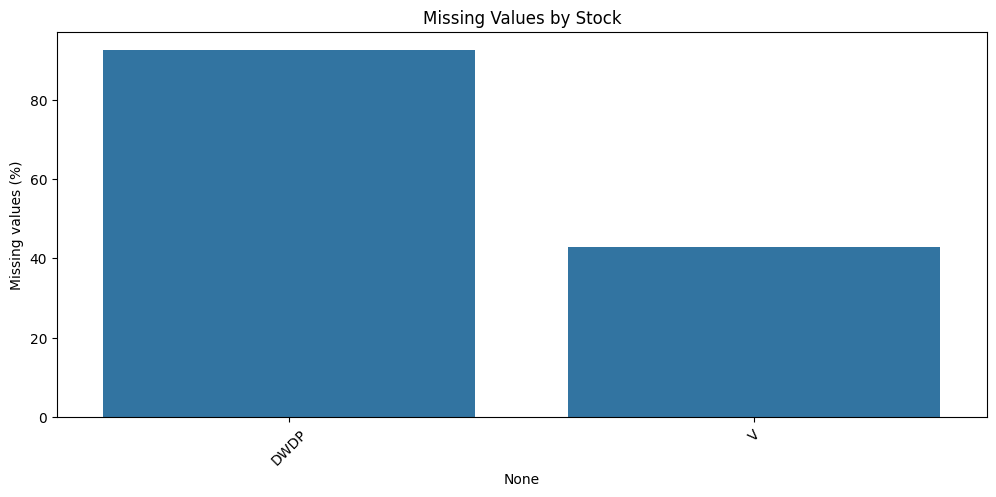

In [3]:
print("Dataset info:")
display(df_raw.info())

print("Duplicate rows:", df_raw.duplicated().sum())
missing_counts = df_raw.isna().sum()
missing_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing Percentage": 100 * missing_counts / len(df_raw)
})
display(missing_summary[missing_summary["Missing Values"] > 0].sort_values("Missing Percentage", ascending=False))

plt.figure(figsize=(12, 5))
ms = missing_summary[missing_summary["Missing Values"] > 0].sort_values("Missing Percentage", ascending=False)
if len(ms):
    sns.barplot(x=ms.index, y=ms["Missing Percentage"])
    plt.title("Missing Values by Stock")
    plt.ylabel("Missing values (%)")
    plt.xticks(rotation=45)
    plt.show()
else:
    print("No missing values.")

## 4. Clean dataset and calculate daily returns

In [4]:
df = df_raw.copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"]).set_index("Date").sort_index()

# Dataset inspection identified these columns as highly incomplete.
columns_to_remove = [c for c in ["DWDP", "V"] if c in df.columns]
df_clean = df.drop(columns=columns_to_remove).dropna()

print("Removed columns:", columns_to_remove)
print("Cleaned shape:", df_clean.shape)
print("Remaining missing cells:", int(df_clean.isna().sum().sum()))
display(df_clean.head())

# Simple daily percentage returns
returns = df_clean.pct_change().dropna()
print("Returns shape:", returns.shape)
display(returns.head())

Removed columns: ['DWDP', 'V']
Cleaned shape: (4804, 28)
Remaining missing cells: 0


,MMM,AXP,AAPL,BA,CAT,CVX,CSCO,KO,DIS,XOM,...,MSFT,NKE,PFE,PG,TRV,UTX,UNH,VZ,WMT,WBA
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,29.847043,35.476634,3.530576,26.650218,14.560887,21.582046,43.003876,16.983583,23.522220,23.862240,...,38.135101,4.701180,16.746856,32.227726,20.158885,21.319030,5.841355,22.564221,47.337599,21.713237
2000-01-04,28.661131,34.134275,3.232839,26.610431,14.372251,21.582046,40.577200,17.040950,24.899860,23.405167,...,36.846046,4.445214,16.121738,31.596399,19.890099,20.445803,5.766368,21.833915,45.566248,20.907354
2000-01-05,30.122175,33.959430,3.280149,28.473758,14.914205,22.049145,40.895453,17.228147,25.781550,24.569179,...,37.235380,4.702157,16.415912,31.325831,20.085579,20.254784,5.753327,22.564221,44.503437,21.097421
2000-01-06,31.877325,33.959430,2.996290,28.553331,15.459153,22.903343,39.781569,17.210031,24.899860,25.958680,...,35.988857,4.677733,16.972739,32.438168,20.122232,20.998392,5.964159,22.449405,45.126952,20.527220
2000-01-07,32.509812,34.433913,3.138219,29.382213,15.962182,23.305926,42.128682,18.342270,24.506249,25.882501,...,36.459983,4.677733,18.123166,35.023602,20.922479,21.830687,6.662948,22.282692,48.535033,21.051805


Returns shape: (4803, 28)


,MMM,AXP,AAPL,BA,CAT,CVX,CSCO,KO,DIS,XOM,...,MSFT,NKE,PFE,PG,TRV,UTX,UNH,VZ,WMT,WBA
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-04,-0.039733,-0.037838,-0.084331,-0.001493,-0.012955,0.000000,-0.056429,0.003378,0.058568,-0.019155,...,-0.033802,-0.054447,-0.037327,-0.019590,-0.013333,-0.040960,-0.012837,-0.032366,-0.037420,-0.037115
2000-01-05,0.050976,-0.005122,0.014634,0.070022,0.037708,0.021643,0.007843,0.010985,0.035409,0.049733,...,0.010567,0.057802,0.018247,-0.008563,0.009828,-0.009343,-0.002262,0.033448,-0.023325,0.009091
2000-01-06,0.058268,0.000000,-0.086538,0.002795,0.036539,0.038741,-0.027237,-0.001052,-0.034198,0.056555,...,-0.033477,-0.005194,0.033920,0.035509,0.001825,0.036713,0.036645,-0.005088,0.014011,-0.027027
2000-01-07,0.019841,0.013972,0.047368,0.029029,0.032539,0.017577,0.059000,0.065789,-0.015808,-0.002935,...,0.013091,0.000000,0.067781,0.079703,0.039769,0.039636,0.117165,-0.007426,0.075522,0.025556
2000-01-10,-0.004864,0.014436,-0.017588,-0.013992,-0.032827,-0.026907,0.036827,-0.031934,0.152586,-0.014010,...,0.007268,0.016917,-0.001739,-0.005150,-0.018102,0.009844,-0.017289,-0.005271,-0.018248,0.029252


## 5. EDA — summary statistics, stock prices, returns and correlation

In [5]:
display(df_clean.describe().T)

,count,mean,std,min,25%,50%,75%,max
MMM,4804.0,86.768590,53.941623,25.140195,51.191601,63.513883,122.906370,251.980826
AXP,4804.0,49.659383,22.564051,8.713025,34.078903,42.274116,66.815558,112.420728
AAPL,4804.0,49.106634,55.020296,0.827607,3.899987,23.316182,84.007174,231.260273
BA,4804.0,85.481517,79.084514,17.463252,37.406768,58.436552,112.996317,411.110000
CAT,4804.0,56.697445,34.663396,9.247340,26.335348,53.047521,76.487605,166.832487
CVX,4804.0,61.735451,31.713863,17.565805,31.820217,56.941779,91.687905,128.679825
CSCO,4804.0,21.652896,10.074094,6.842430,14.910132,18.577993,24.649935,63.698248
KO,4804.0,24.983814,10.611235,11.698790,15.419998,20.563342,34.927140,50.400000
DIS,4804.0,46.367724,32.733220,11.018313,22.044106,29.521283,75.833054,117.972904
XOM,4804.0,54.740800,20.686994,19.491235,33.381211,57.192944,73.712054,88.851798


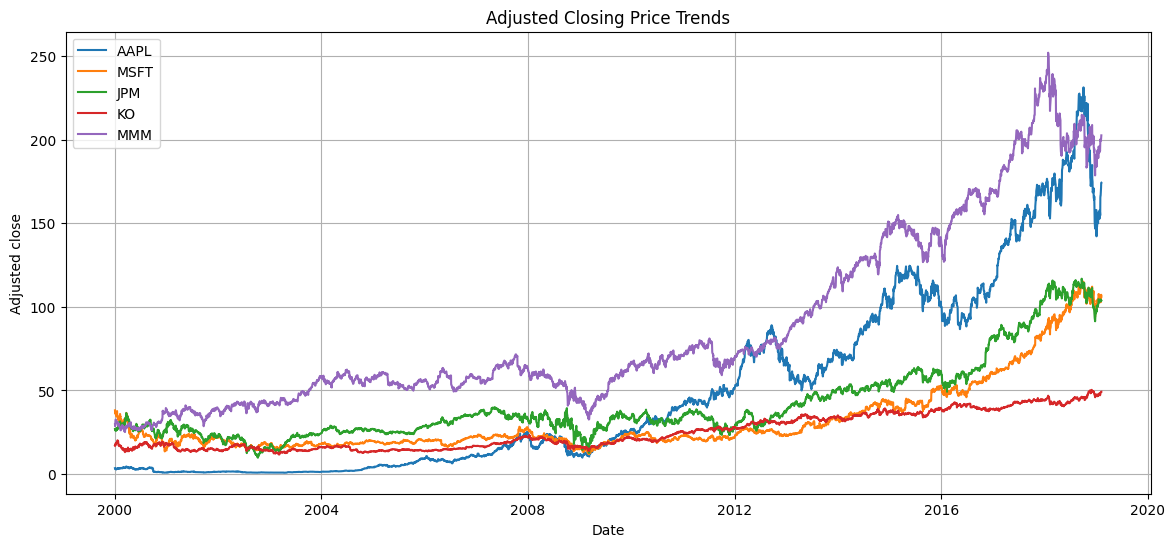

In [6]:
selected_stocks = [s for s in ["AAPL", "MSFT", "JPM", "KO", "MMM"] if s in df_clean.columns]
plt.figure(figsize=(14, 6))
for stock in selected_stocks:
    plt.plot(df_clean.index, df_clean[stock], label=stock)
plt.title("Adjusted Closing Price Trends")
plt.xlabel("Date"); plt.ylabel("Adjusted close"); plt.legend(); plt.grid(True); plt.show()

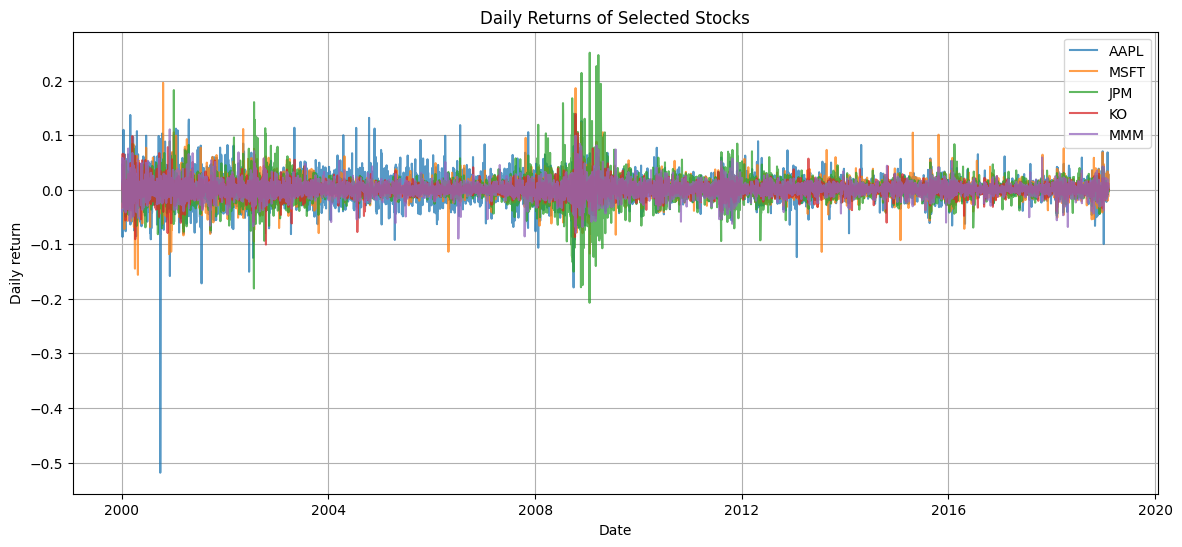

In [7]:
plt.figure(figsize=(14, 6))
for stock in selected_stocks:
    plt.plot(returns.index, returns[stock], label=stock, alpha=0.75)
plt.title("Daily Returns of Selected Stocks")
plt.xlabel("Date"); plt.ylabel("Daily return"); plt.legend(); plt.grid(True); plt.show()

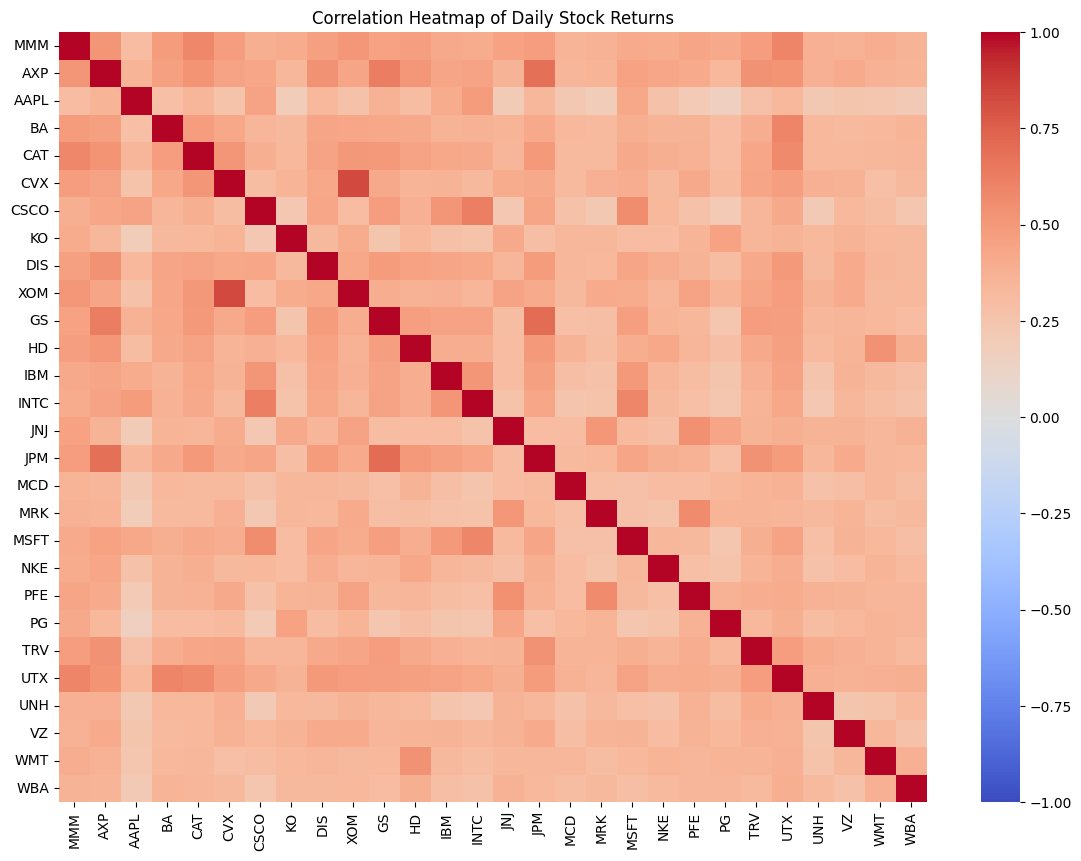

In [8]:
correlation_matrix = returns.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Daily Stock Returns")
plt.show()

,Annualized Mean Return,Annualized Volatility
AAPL,0.292512,0.409385
JPM,0.147005,0.392111
CSCO,0.081103,0.390890
INTC,0.098603,0.371414
GS,0.120695,0.370954
AXP,0.119651,0.354729
CAT,0.166783,0.321596
UNH,0.249998,0.314096
HD,0.122092,0.309096
MSFT,0.100371,0.305833


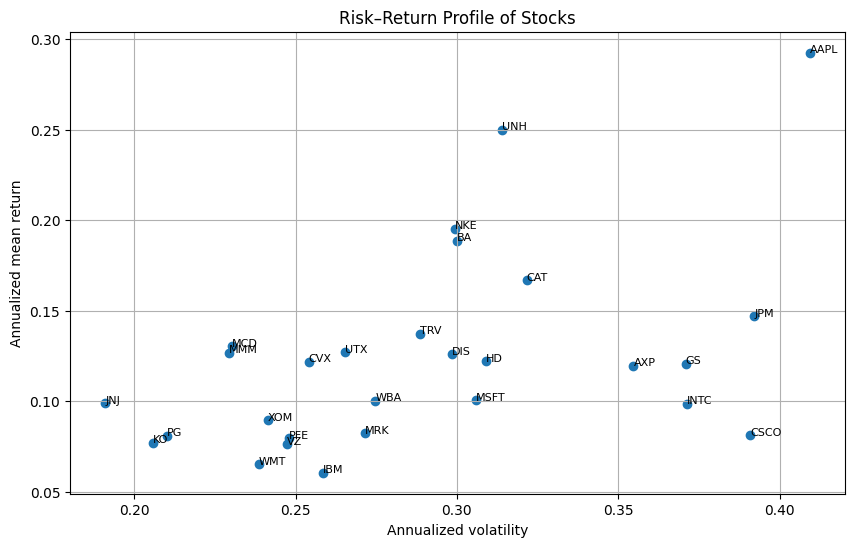

In [9]:
annualized_volatility = returns.std() * np.sqrt(ANNUALIZATION)
annualized_mean_return = returns.mean() * ANNUALIZATION
risk_return = pd.DataFrame({
    "Annualized Mean Return": annualized_mean_return,
    "Annualized Volatility": annualized_volatility
}).sort_values("Annualized Volatility", ascending=False)
display(risk_return)

plt.figure(figsize=(10, 6))
plt.scatter(risk_return["Annualized Volatility"], risk_return["Annualized Mean Return"])
for ticker in risk_return.index:
    plt.annotate(ticker, (risk_return.loc[ticker, "Annualized Volatility"],
                          risk_return.loc[ticker, "Annualized Mean Return"]), fontsize=8)
plt.title("Risk–Return Profile of Stocks")
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.grid(True); plt.show()

## 6. PCA and Eigen Portfolios

PCA is applied to the daily returns without standardizing each stock to unit variance. This means PCA is based on the covariance structure of returns, as described in the project brief.

Each PCA component is an eigenvector. Its coefficients give the stock loadings for that component. PCA signs are mathematically arbitrary (a component and its negative are equivalent).

In [10]:
pca = PCA()
pca_scores = pca.fit_transform(returns.values)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Number of components:", len(explained_variance))
print("Components for >=90% variance:", int(np.searchsorted(cumulative_variance, 0.90) + 1))
print("Components for >=95% variance:", int(np.searchsorted(cumulative_variance, 0.95) + 1))

Number of components: 28
Components for >=90% variance: 19
Components for >=95% variance: 23


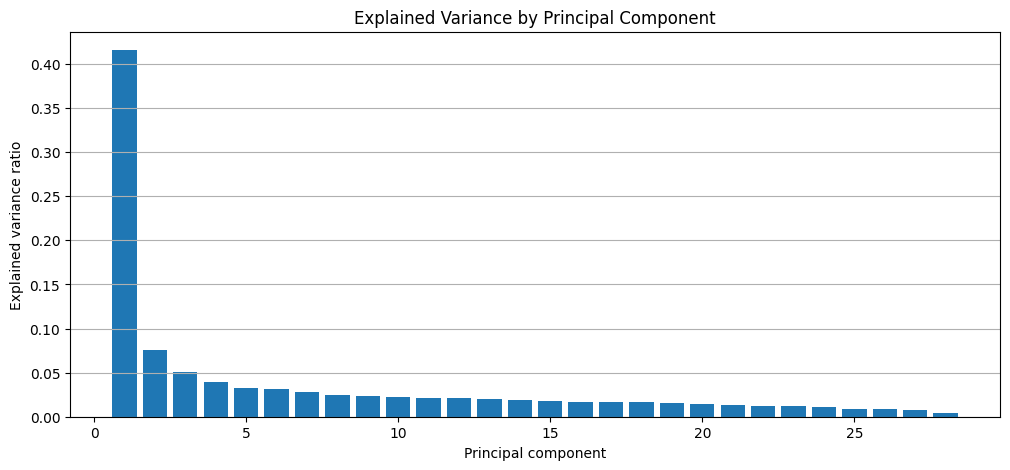

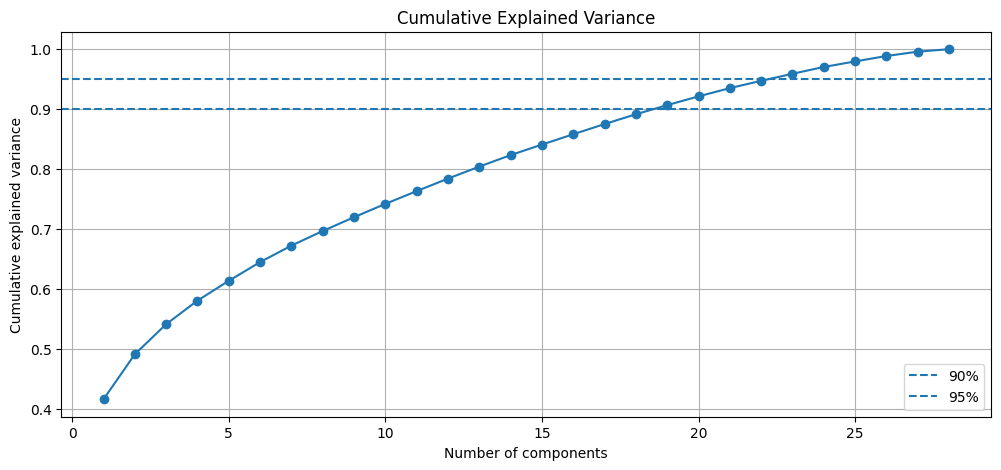

In [11]:
plt.figure(figsize=(12, 5))
plt.bar(np.arange(1, len(explained_variance)+1), explained_variance)
plt.title("Explained Variance by Principal Component")
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio")
plt.grid(axis="y"); plt.show()

plt.figure(figsize=(12, 5))
plt.plot(np.arange(1, len(cumulative_variance)+1), cumulative_variance, marker="o")
plt.axhline(0.90, linestyle="--", label="90%")
plt.axhline(0.95, linestyle="--", label="95%")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.legend(); plt.grid(True); plt.show()

First 10 stock loadings for PC1:


,PC1
MMM,0.159524
AXP,0.274981
AAPL,0.228401
BA,0.190915
CAT,0.224926
CVX,0.159295
CSCO,0.260209
KO,0.100290
DIS,0.204340
XOM,0.153811


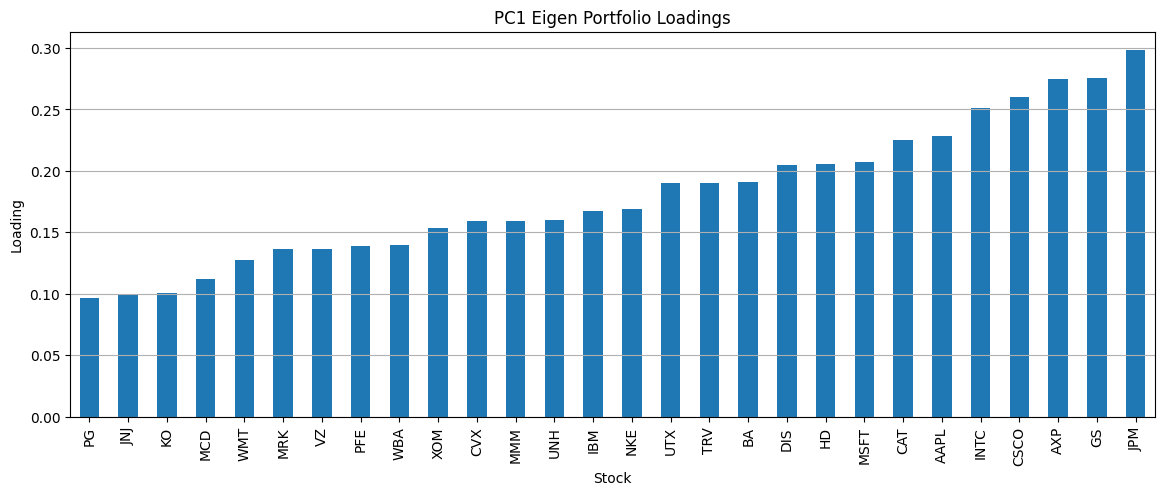

In [12]:
eigen_portfolio_weights = pd.DataFrame(
    pca.components_.T,
    index=returns.columns,
    columns=[f"PC{i+1}" for i in range(len(returns.columns))]
)
print("First 10 stock loadings for PC1:")
display(eigen_portfolio_weights[["PC1"]].head(10))

plt.figure(figsize=(14, 5))
eigen_portfolio_weights["PC1"].sort_values().plot(kind="bar")
plt.title("PC1 Eigen Portfolio Loadings")
plt.xlabel("Stock"); plt.ylabel("Loading"); plt.grid(axis="y"); plt.show()

### Eigen portfolio return series and performance

The PCA eigenvector provides stock loadings. To estimate the return of a fixed-weight statistical portfolio, we apply the normalized PC1 loadings to the original daily stock returns. PCA signs are arbitrary, so the notebook orients the weights consistently and normalizes gross exposure (sum of absolute weights) to one. The portfolio may contain positive and negative weights, so it represents a long/short statistical portfolio, not a long-only allocation.

The metrics are historical estimates, not forecasts. The portfolio is treated as fixed-weight here; transaction costs, rebalancing, and financing costs are not included.

PC1 Eigen Portfolio Weights:


,Weight
MMM,0.031546
AXP,0.054378
AAPL,0.045167
BA,0.037754
CAT,0.044479
CVX,0.031501
CSCO,0.051457
KO,0.019833
DIS,0.040408
XOM,0.030416


PC1 Eigen Portfolio Performance:


,Annualized mean return,Annualized volatility,Sharpe ratio (risk-free rate = 0),Maximum drawdown
PC1 Eigen Portfolio,0.128408,0.199016,0.645217,-0.488115


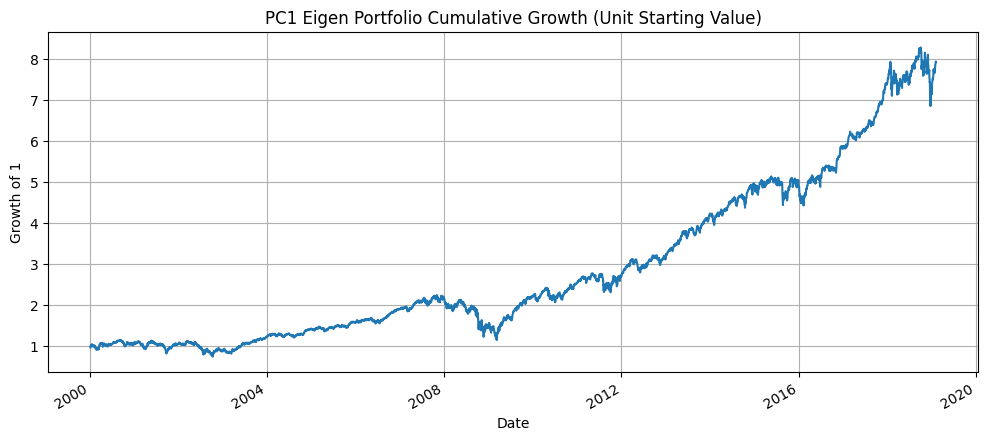

In [13]:
# Define portfolio performance metrics (also used in the benchmark section)
def performance_metrics(series, periods=252):
    series = pd.Series(series).dropna()
    annualized_return = series.mean() * periods
    annualized_volatility = series.std(ddof=1) * np.sqrt(periods)
    sharpe_ratio = (
        annualized_return / annualized_volatility
        if annualized_volatility != 0 else np.nan
    )
    cumulative_growth = (1 + series).cumprod()
    maximum_drawdown = (
        cumulative_growth / cumulative_growth.cummax() - 1
    ).min()

    return {
        "Annualized mean return": annualized_return,
        "Annualized volatility": annualized_volatility,
        "Sharpe ratio (risk-free rate = 0)": sharpe_ratio,
        "Maximum drawdown": maximum_drawdown
    }

# Construct PC1 Eigen Portfolio from PCA loadings.
# The sign of a PCA component is arbitrary; orient it consistently.
pc1_weights = pca.components_[0].copy()
if pc1_weights.sum() < 0:
    pc1_weights = -pc1_weights

# Normalize gross exposure (sum of absolute weights) to 1.
pc1_weights = pc1_weights / np.abs(pc1_weights).sum()

# Apply weights to original daily returns to get portfolio returns.
pc1_returns = returns.dot(pc1_weights)

print("PC1 Eigen Portfolio Weights:")
display(pd.DataFrame({"Weight": pc1_weights}, index=returns.columns))

pc1_metrics = performance_metrics(pc1_returns)
print("PC1 Eigen Portfolio Performance:")
display(pd.DataFrame([pc1_metrics], index=["PC1 Eigen Portfolio"]))

plt.figure(figsize=(12, 5))
(1 + pc1_returns).cumprod().plot()
plt.title("PC1 Eigen Portfolio Cumulative Growth (Unit Starting Value)")
plt.ylabel("Growth of 1")
plt.grid(True)
plt.show()

## 7. Benchmark comparison

The CSV contains individual DJIA constituents but not necessarily an index series. We use an equal-weighted portfolio of the retained constituent returns as a transparent comparison proxy. This is **not exactly the DJIA index**; label it as an equal-weighted stock basket in the report. If an actual DJIA benchmark series is obtained, replace this proxy.

,Annualized mean return,Annualized volatility,Sharpe ratio (risk-free rate = 0),Maximum drawdown
PC1 Eigen Portfolio (statistical),0.128408,0.199016,0.645217,-0.488115
Equal-weighted stock basket (proxy),0.123639,0.182816,0.676303,-0.451806


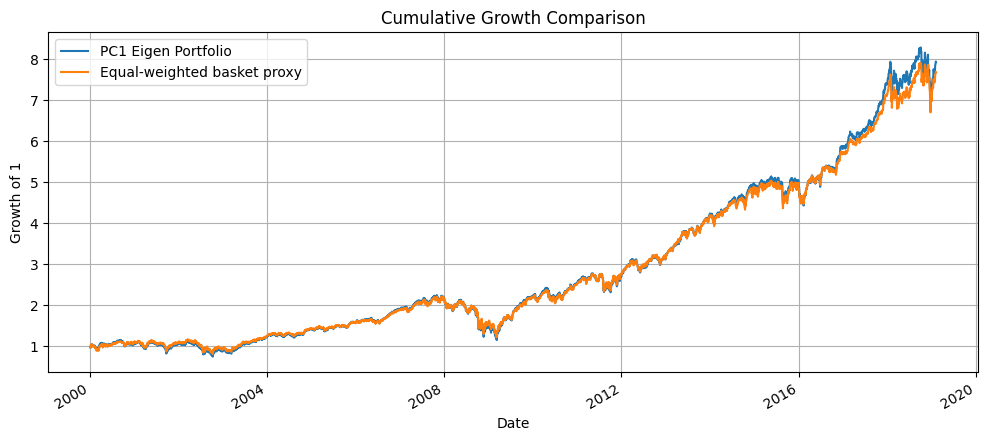

In [14]:
# Compare PC1 Eigen Portfolio with an equal-weighted basket proxy.
equal_weight_returns = returns.mean(axis=1)

benchmark_metrics = performance_metrics(equal_weight_returns)
comparison = pd.DataFrame(
    [pc1_metrics, benchmark_metrics],
    index=[
        "PC1 Eigen Portfolio (statistical)",
        "Equal-weighted stock basket (proxy)"
    ]
)

display(comparison)

growth = pd.DataFrame({
    "PC1 Eigen Portfolio": (1 + pc1_returns).cumprod(),
    "Equal-weighted basket proxy": (1 + equal_weight_returns).cumprod()
})
growth.plot(figsize=(12, 5))
plt.title("Cumulative Growth Comparison")
plt.ylabel("Growth of 1")
plt.grid(True)
plt.show()

## 8. Machine Learning task

The assignment asks for regression/classification across multiple frameworks but does not specify a target variable. For this reproducible implementation, the target is the next trading day's equal-weighted basket return, predicted from lagged daily returns of the retained stocks. The chronological split avoids randomly mixing future observations into training.

This is an illustrative prediction task; it does not establish a profitable trading strategy. Model comparisons are reported using RMSE, MAE and R².

In [15]:
# Feature rows at time t use information through t; target is basket return at t+1.
target_series = returns.mean(axis=1).shift(-1).rename("target_next_day_return")
X_all = returns.copy()
dataset_ml = X_all.join(target_series).dropna()
X = dataset_ml.drop(columns=["target_next_day_return"])
y = dataset_ml["target_next_day_return"]

split_index = int(len(dataset_ml) * (1 - TEST_SIZE))
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Train rows:", len(X_train), "Test rows:", len(X_test))
print("Train period:", X_train.index.min(), "to", X_train.index.max())
print("Test period:", X_test.index.min(), "to", X_test.index.max())

Train rows: 3841 Test rows: 961
Train period: 2000-01-04 00:00:00 to 2015-04-13 00:00:00
Test period: 2015-04-14 00:00:00 to 2019-02-05 00:00:00


### Utility functions for metrics and results

In [16]:
results = []
predictions = {}

def evaluate_model(name, y_true, y_pred, notes=""):
    y_pred = np.asarray(y_pred).reshape(-1)
    row = {
        "Model": name,
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
        "Notes": notes
    }
    results.append(row)
    predictions[name] = y_pred
    print(row)
    return row

# Baseline: predicts training mean for every test point
baseline_pred = np.repeat(y_train.mean(), len(y_test))
evaluate_model("Mean baseline", y_test, baseline_pred, "Reference baseline")

{'Model': 'Mean baseline', 'RMSE': 0.00836318199565991, 'MAE': 0.005665747430776272, 'R2': -9.087079311242974e-09, 'Notes': 'Reference baseline'}


{'Model': 'Mean baseline',
 'RMSE': 0.00836318199565991,
 'MAE': 0.005665747430776272,
 'R2': -9.087079311242974e-09,
 'Notes': 'Reference baseline'}

## 9. XGBoost Regression

In [17]:
# Install only if needed
try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=300, max_depth=3, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8,
    objective="reg:squarederror", random_state=RANDOM_STATE
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
evaluate_model("XGBoost", y_test, xgb_pred, "Gradient-boosted trees")

{'Model': 'XGBoost', 'RMSE': 0.00852228573442041, 'MAE': 0.005743428506098999, 'R2': -0.03841054695655588, 'Notes': 'Gradient-boosted trees'}


{'Model': 'XGBoost',
 'RMSE': 0.00852228573442041,
 'MAE': 0.005743428506098999,
 'R2': -0.03841054695655588,
 'Notes': 'Gradient-boosted trees'}

## 10. Keras Regression

In [18]:
try:
    import tensorflow as tf
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tensorflow"])
    import tensorflow as tf

tf.keras.utils.set_random_seed(RANDOM_STATE)
keras_scaler = StandardScaler()
X_train_keras = keras_scaler.fit_transform(X_train)
X_test_keras = keras_scaler.transform(X_test)

keras_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.15),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])
keras_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
keras_model.fit(X_train_keras, y_train, epochs=30, batch_size=32,
                validation_split=0.1, shuffle=False, verbose=0)
keras_pred = keras_model.predict(X_test_keras, verbose=0).reshape(-1)
evaluate_model("Keras", y_test, keras_pred, "Dense neural network")

{'Model': 'Keras', 'RMSE': 0.00884027754324332, 'MAE': 0.00610218189345198, 'R2': -0.11734864950804402, 'Notes': 'Dense neural network'}


{'Model': 'Keras',
 'RMSE': 0.00884027754324332,
 'MAE': 0.00610218189345198,
 'R2': -0.11734864950804402,
 'Notes': 'Dense neural network'}

## 11. fastai Tabular Regression

fastai is a PyTorch-based high-level framework. Here, the data are represented as a tabular dataset with continuous input columns. If the package or API fails in the current Colab environment, the exception is recorded and the notebook continues.

In [19]:
try:
    try:
        from fastai.tabular.all import *
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "fastai"])
        from fastai.tabular.all import *

    fastai_train = X_train.copy()
    fastai_train["target"] = y_train.values
    fastai_test = X_test.copy()

    to = TabularPandas(
        fastai_train,
        cont_names=list(X_train.columns),
        cat_names=[],
        y_names="target",
        y_block=RegressionBlock(),
        splits=(list(range(len(fastai_train))), [])
    )
    dls = to.dataloaders(bs=64)
    fastai_learner = tabular_learner(dls, layers=[64, 32], loss_func=MSELossFlat())
    fastai_learner.fit_one_cycle(8, 1e-2)

    fastai_test_dl = dls.test_dl(fastai_test)
    fastai_pred = fastai_learner.get_preds(dl=fastai_test_dl)[0].numpy().reshape(-1)
    evaluate_model("PyTorch + fastai", y_test, fastai_pred, "fastai tabular learner")
except Exception as e:
    print("fastai model could not run in this environment:", repr(e))

epoch,train_loss,valid_loss,time
0,0.037815,None,00:00
1,0.009947,None,00:00
2,0.003127,None,00:00
3,0.001126,None,00:00
4,0.000525,None,00:00
5,0.000302,None,00:00
6,0.000219,None,00:00
7,0.000183,None,00:00


{'Model': 'PyTorch + fastai', 'RMSE': 0.009342510600668753, 'MAE': 0.00667751608935614, 'R2': -0.24791241955455323, 'Notes': 'fastai tabular learner'}


## 12. PyTorch with TabNet

In [20]:
try:
    try:
        from pytorch_tabnet.tab_model import TabNetRegressor
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pytorch-tabnet"])
        from pytorch_tabnet.tab_model import TabNetRegressor

    tabnet_scaler = StandardScaler()
    X_train_tab = tabnet_scaler.fit_transform(X_train).astype(np.float32)
    X_test_tab = tabnet_scaler.transform(X_test).astype(np.float32)
    y_train_tab = y_train.values.reshape(-1, 1).astype(np.float32)
    y_test_tab = y_test.values.reshape(-1, 1).astype(np.float32)

    tabnet_model = TabNetRegressor(seed=RANDOM_STATE, verbose=0)
    tabnet_model.fit(
        X_train_tab, y_train_tab,
        eval_set=[(X_test_tab, y_test_tab)],
        max_epochs=50, patience=10,
        batch_size=256, virtual_batch_size=128,
        num_workers=0
    )
    tabnet_pred = tabnet_model.predict(X_test_tab).reshape(-1)
    evaluate_model("PyTorch + TabNet", y_test, tabnet_pred, "Attention-based tabular model")
except Exception as e:
    print("TabNet model could not run in this environment:", repr(e))

Stop training because you reached max_epochs = 50 with best_epoch = 48 and best_val_0_mse = 7e-05
{'Model': 'PyTorch + TabNet', 'RMSE': 0.008438142134177385, 'MAE': 0.0057317303368429355, 'R2': -0.018006571016866424, 'Notes': 'Attention-based tabular model'}


## 13. PyTorch Lightning Flash

Lightning Flash's tabular API has changed across releases and is not consistently maintained in current Colab environments. This section tries the documented package/API if available. A failure is printed rather than stopping the entire notebook. If it fails, use the error output and installed version to adapt the API; do not claim a Flash result in the report unless it actually trained.

In [21]:
# PyTorch Lightning Flash (Tabular) — compatibility check and training attempt.
# Flash is an older framework and may not support the current Colab/Python/PyTorch versions.
# This cell will NOT stop the rest of the notebook if installation or training fails.

flash_status = "NOT RUN"
flash_error = None

try:
    # First try importing an already-installed compatible Flash package.
    try:
        import flash
        from flash.tabular import TabularData, TabularRegressor
    except Exception:
        # Install the framework package. Do not silently substitute another framework.
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q",
            "lightning-flash[tabular]==0.8.2"
        ])
        import flash
        from flash.tabular import TabularData, TabularRegressor

    flash_train_df = X_train.copy()
    flash_train_df["target"] = y_train.to_numpy()
    flash_test_df = X_test.copy()
    flash_test_df["target"] = y_test.to_numpy()

    flash_datamodule = TabularData.from_data_frame(
        "regression",
        train_data_frame=flash_train_df,
        val_data_frame=flash_test_df,
        target="target",
        batch_size=64
    )

    flash_model = TabularRegressor.from_data(flash_datamodule)
    flash_trainer = flash.Trainer(
        max_epochs=5,
        accelerator="auto",
        devices=1,
        enable_checkpointing=False,
        logger=False
    )
    flash_trainer.fit(flash_model, datamodule=flash_datamodule)

    flash_output = flash_trainer.predict(
        flash_model, datamodule=flash_datamodule
    )
    flash_pred = np.concatenate([
        item.detach().cpu().numpy().reshape(-1)
        if hasattr(item, "detach") else np.asarray(item).reshape(-1)
        for item in flash_output
    ])[:len(y_test)]

    if len(flash_pred) == len(y_test):
        evaluate_model(
            "PyTorch + Lightning Flash",
            y_test,
            flash_pred,
            "Lightning Flash tabular regressor"
        )
        flash_status = "COMPLETED"
    else:
        raise ValueError(
            f"Expected {len(y_test)} predictions, received {len(flash_pred)}"
        )

except Exception as e:
    flash_status = "FAILED — framework/environment compatibility"
    flash_error = repr(e)
    print("Lightning Flash could not be executed in this Colab environment.")
    print("Exact error:", flash_error)
    print("Do not report a metric for Lightning Flash unless training completes.")

print("Lightning Flash status:", flash_status)

Lightning Flash could not be executed in this Colab environment.
Exact error: CalledProcessError(1, ['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'lightning-flash[tabular]==0.8.2'])
Do not report a metric for Lightning Flash unless training completes.
Lightning Flash status: FAILED — framework/environment compatibility


## 14. Compare model metrics

## 13A. Lightning Flash result from the Mac environment (separate verified run)

The Colab Flash installation attempt above failed because the package installation returned a `CalledProcessError`. A separate run was therefore completed on macOS using Python 3.10.22, Lightning Flash 0.8.2 and the TabNet backbone.

The initial unstandardized-target run produced implausibly large predictions (range approximately -1.487 to 1.602 for a daily-return target) and was **not used**. The corrected run standardized the target using the training-set mean and standard deviation only, then inverse-transformed predictions to the original daily-return scale before evaluation.

Recorded corrected test metrics:
- RMSE = 0.0086015558
- MAE = 0.0059053562
- R² = -0.0578179385

This is a separately executed Mac experiment, not a successful Colab execution of the Flash cell above. Its split contains 3,841 training rows and 961 test rows, matching the chronological 80/20 protocol. The Flash result is slightly worse than the mean baseline (RMSE 0.0083631820, MAE 0.0056657474, R² approximately 0). Do not describe Flash as the best model.

Target standardization was used to stabilize the model's output scale; all reported Flash metrics are calculated after converting predictions back to the original target scale. The model's predictive performance remains weak, so this is a valid completed comparison result, not evidence of useful forecasting skill.


In [22]:
# Add the separately executed, corrected macOS Lightning Flash result to the comparison.
# This records the actual metrics from the verified run; it does not pretend that
# the failed Colab installation cell above completed.
flash_mac_result = {
    "Model": "PyTorch + Lightning Flash (TabNet, target-standardized)",
    "RMSE": 0.0086015558,
    "MAE": 0.0059053562,
    "R2": -0.0578179385,
    "Notes": "Separate macOS run; target standardized on train data and predictions inverse-transformed"
}
if not any(r.get("Model") == flash_mac_result["Model"] for r in results):
    results.append(flash_mac_result)

results_df = pd.DataFrame(results)
display(results_df.sort_values("RMSE"))
results_df.to_csv("eigen_portfolio_model_comparison_with_flash.csv", index=False)
print("Saved: eigen_portfolio_model_comparison_with_flash.csv")


,Model,RMSE,MAE,R2,Notes
0,Mean baseline,0.008363,0.005666,-9.087079e-09,Reference baseline
4,PyTorch + TabNet,0.008438,0.005732,-1.800657e-02,Attention-based tabular model
1,XGBoost,0.008522,0.005743,-3.841055e-02,Gradient-boosted trees
5,"PyTorch + Lightning Flash (TabNet, target-standardized)",0.008602,0.005905,-5.781794e-02,Separate macOS run; target standardized on train data and predictions inverse-transformed
2,Keras,0.008840,0.006102,-1.173486e-01,Dense neural network
3,PyTorch + fastai,0.009343,0.006678,-2.479124e-01,fastai tabular learner


Saved: eigen_portfolio_model_comparison_with_flash.csv


In [23]:
results_df = pd.DataFrame(results)
if len(results_df):
    display(results_df.sort_values("RMSE"))
    results_df.to_csv("eigen_portfolio_model_comparison.csv", index=False)
    print("Saved: eigen_portfolio_model_comparison.csv")
else:
    print("No models completed successfully.")

,Model,RMSE,MAE,R2,Notes
0,Mean baseline,0.008363,0.005666,-9.087079e-09,Reference baseline
4,PyTorch + TabNet,0.008438,0.005732,-1.800657e-02,Attention-based tabular model
1,XGBoost,0.008522,0.005743,-3.841055e-02,Gradient-boosted trees
5,"PyTorch + Lightning Flash (TabNet, target-standardized)",0.008602,0.005905,-5.781794e-02,Separate macOS run; target standardized on train data and predictions inverse-transformed
2,Keras,0.008840,0.006102,-1.173486e-01,Dense neural network
3,PyTorch + fastai,0.009343,0.006678,-2.479124e-01,fastai tabular learner


Saved: eigen_portfolio_model_comparison.csv


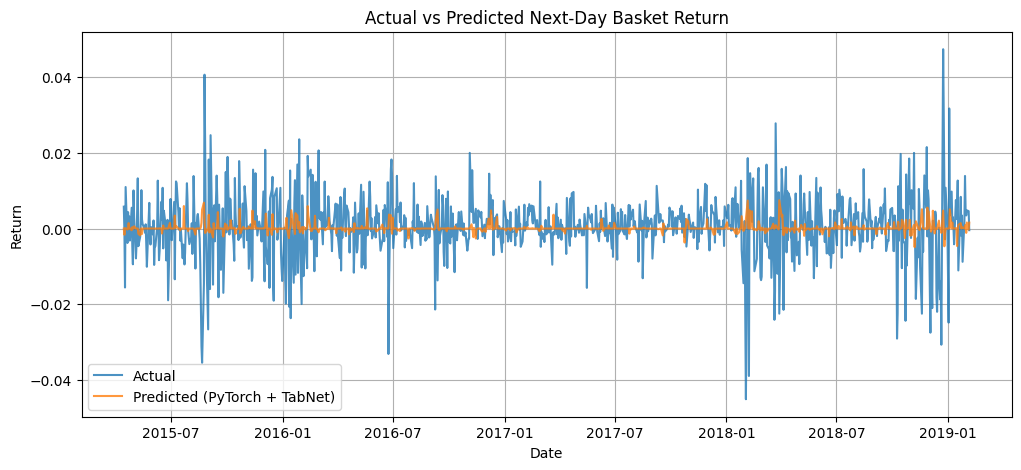

Lowest RMSE among completed non-baseline models: PyTorch + TabNet


In [24]:
if predictions:
    best_name = min(
        [name for name in predictions if name != "Mean baseline"],
        key=lambda name: np.sqrt(mean_squared_error(y_test, predictions[name])),
        default=None
    )
    if best_name:
        plt.figure(figsize=(12, 5))
        plt.plot(y_test.index, y_test.values, label="Actual", alpha=0.8)
        plt.plot(y_test.index, predictions[best_name], label=f"Predicted ({best_name})", alpha=0.8)
        plt.title("Actual vs Predicted Next-Day Basket Return")
        plt.xlabel("Date"); plt.ylabel("Return"); plt.legend(); plt.grid(True); plt.show()
        print("Lowest RMSE among completed non-baseline models:", best_name)

## 15. Simplicity, transparency and efficacy discussion

In [25]:
# This is a qualitative comparison guide. Adjust based on your actual implementation,
# observed model behavior, and what you can explain during the viva.
qualitative_comparison = pd.DataFrame([
    ["XGBoost", "Moderate", "Moderate", "Often strong on tabular data; verify with held-out metrics"],
    ["Keras dense neural network", "Moderate", "Low–moderate", "Can model nonlinearities; needs tuning and scaling"],
    ["PyTorch + fastai", "Moderate–high", "Low–moderate", "High-level PyTorch tabular workflow"],
    ["PyTorch + TabNet", "Low–moderate", "Moderate", "Tabular attention model; training may be more involved"],
    ["PyTorch + Lightning Flash", "Moderate–high", "Low–moderate", "Convenient abstraction, but package/API compatibility can be an issue"]
], columns=["Framework", "Simplicity", "Transparency", "Efficacy (general expectation; not your result)"])
display(qualitative_comparison)

,Framework,Simplicity,Transparency,Efficacy (general expectation; not your result)
0,XGBoost,Moderate,Moderate,Often strong on tabular data; verify with held-out metrics
1,Keras dense neural network,Moderate,Low–moderate,Can model nonlinearities; needs tuning and scaling
2,PyTorch + fastai,Moderate–high,Low–moderate,High-level PyTorch tabular workflow
3,PyTorch + TabNet,Low–moderate,Moderate,Tabular attention model; training may be more involved
4,PyTorch + Lightning Flash,Moderate–high,Low–moderate,"Convenient abstraction, but package/API compatibility can be an issue"


## 16. Report-ready findings and limitations

Use the output tables and graphs above to write your findings. Do not copy example results from elsewhere: fill in the real metrics produced by your run.

### Methodology summary
1. Loaded historical adjusted close prices for DJIA constituent stocks.
2. Examined missingness and duplicates.
3. Excluded the highly incomplete DWDP and V columns; retained complete stock histories.
4. Computed daily percentage returns.
5. Performed EDA using price trends, return plots, correlation, and annualized risk-return summaries.
6. Applied PCA to the covariance structure of daily returns.
7. Interpreted eigenvectors as stock loadings and principal-component scores as statistical portfolio returns.
8. Compared PC1 with an equal-weighted retained-stock basket proxy.
9. Trained models using a chronological split to predict the next-day basket return and compared RMSE, MAE, and R².

### Limitations
- Historical performance does not guarantee future returns.
- The retained-stock equal-weighted basket is a proxy, not the actual DJIA index.
- Excluding incomplete tickers changes the universe under study.
- The next-day return prediction target is an implementation assumption because the project brief does not specify a target.
- Transaction costs, slippage, turnover, and constraints are not modeled.
- Some required libraries (especially Lightning Flash) may have version compatibility issues. Report only completed experiments.

### Conclusion prompt
Describe which PCA components captured the largest share of variance, what PC1 loadings reveal, how PC1 risk/return compared with the equal-weighted proxy, and which ML framework had the best actual test metrics. Avoid claiming a model is best unless the computed comparison supports it.

## 17. Save notebook outputs

In [26]:
# Download the model metrics CSV from Colab if desired:
# from google.colab import files
# files.download("eigen_portfolio_model_comparison.csv")
print("Notebook run sections completed. Save the notebook using File → Save.")

Notebook run sections completed. Save the notebook using File → Save.


## Verified PCA loading values and figures (recalculated from supplied CSV)

This section reproduces the notebook's PCA method on `Dow_adjcloses.csv`: remove `DWDP` and `V`, compute percentage daily returns, and fit PCA directly to the 28 return columns (without standardization). It prints the full PC1 loading table and generates the scree, cumulative-variance, loading, and portfolio-growth plots.

PC1 LOADING TABLE


,Raw PC1 loading,Normalized portfolio weight
PG,0.096845,0.019151
JNJ,0.099939,0.019763
KO,0.100290,0.019833
MCD,0.111703,0.022089
WMT,0.127482,0.025210
MRK,0.136544,0.027002
VZ,0.136698,0.027032
PFE,0.138505,0.027390
WBA,0.139260,0.027539
XOM,0.153811,0.030416


Return matrix shape: (4803, 28)
Components for >=90% variance: 19
Components for >=95% variance: 23


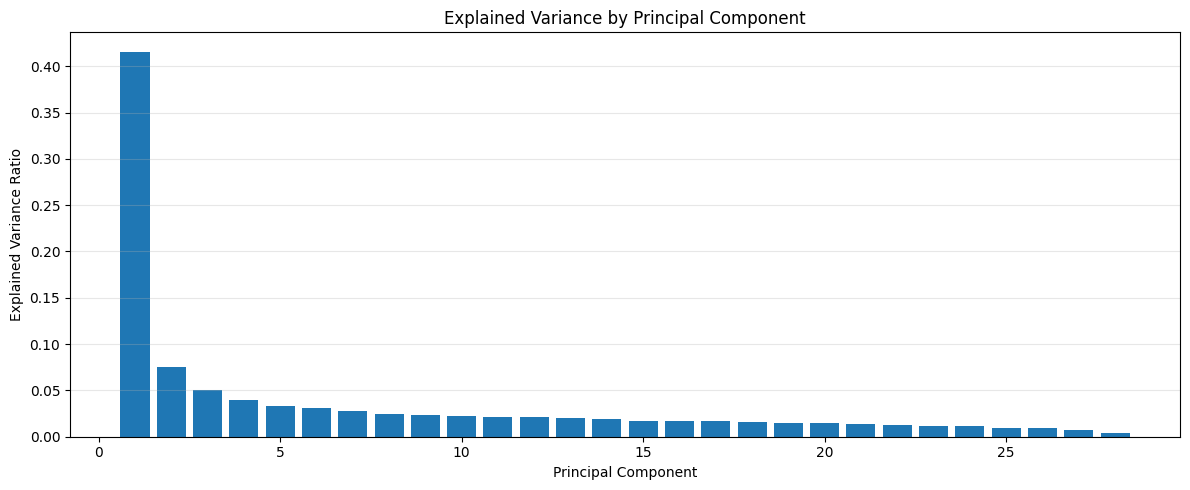

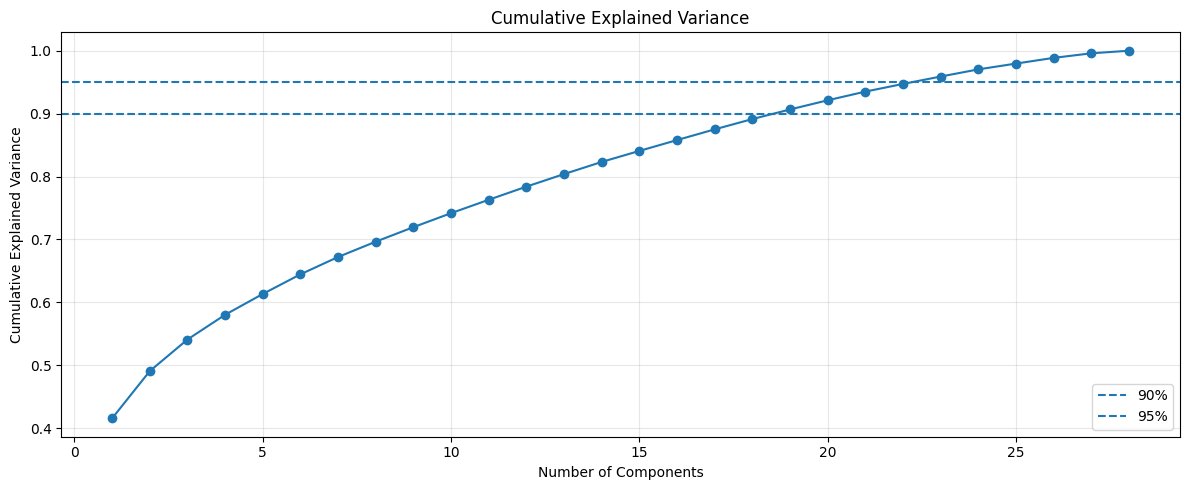

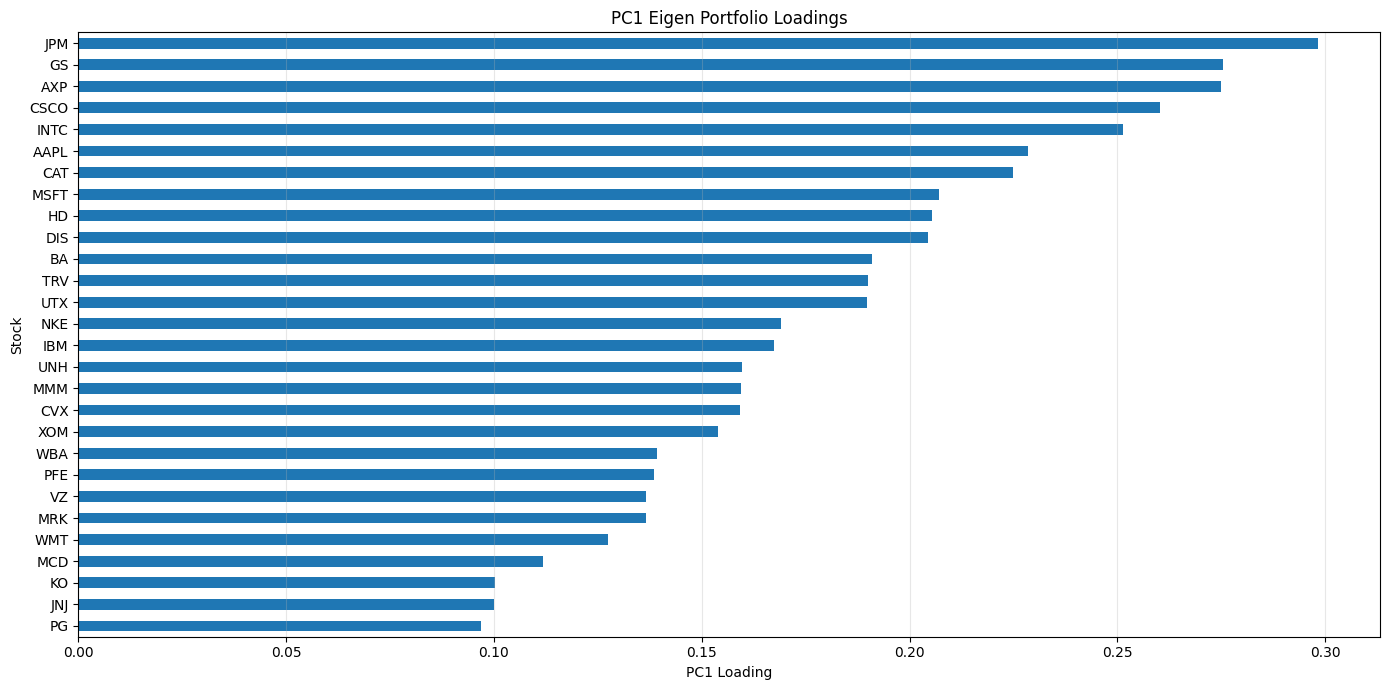

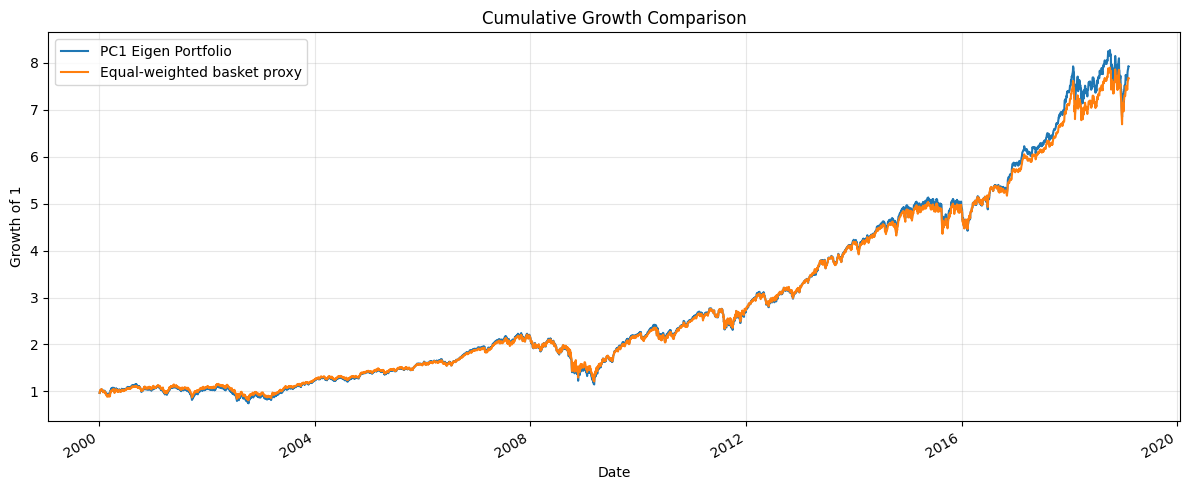


PCA EXECUTION COMPLETED SUCCESSFULLY
Saved figures: eigen_portfolio_figures
Saved loading table: verified_pc1_loadings.csv
Number of stocks: 28


In [28]:

# ============================================================
# REPRODUCIBLE PCA OUTPUTS AND EIGEN PORTFOLIO FIGURES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Locate the dataset automatically
DATA_PATH = "/content/Dow_adjcloses.csv"

if not os.path.exists(DATA_PATH):
    home_path = os.path.expanduser("~/Dow_adjcloses.csv")

    if os.path.exists(home_path):
        DATA_PATH = home_path
    else:
        print("Dataset not found. Please upload Dow_adjcloses.csv.")
        from google.colab import files
        uploaded = files.upload()

        matching_files = [
            name for name in uploaded
            if name.lower().endswith(".csv")
        ]

        if not matching_files:
            raise FileNotFoundError(
                "No CSV file uploaded. Please upload Dow_adjcloses.csv."
            )

        DATA_PATH = os.path.join("/content", matching_files[0])

# 2. Load and clean dataset
df_pca = pd.read_csv(DATA_PATH)

if "Date" not in df_pca.columns:
    raise ValueError("Dataset must contain a Date column.")

df_pca["Date"] = pd.to_datetime(df_pca["Date"])
df_pca = df_pca.drop(
    columns=["DWDP", "V"], errors="ignore"
)
df_pca = df_pca.set_index("Date").sort_index()

# Keep numeric stock columns
df_pca = df_pca.select_dtypes(include=[np.number])

# 3. Calculate daily returns
returns_pca = df_pca.pct_change().dropna()

if returns_pca.empty or returns_pca.shape[1] < 2:
    raise ValueError("Insufficient stock return data for PCA.")

if not np.isfinite(returns_pca.values).all():
    raise ValueError("Return data contains invalid values.")

# 4. Apply PCA (without standardization)
pca_verified = PCA()
pca_verified.fit(returns_pca.values)

evr_verified = pca_verified.explained_variance_ratio_
cum_verified = np.cumsum(evr_verified)

# 5. Calculate PC1 loadings
pc1_raw = pd.Series(
    pca_verified.components_[0],
    index=returns_pca.columns,
    name="Raw PC1 loading"
)

# Orient component consistently
if pc1_raw.sum() < 0:
    pc1_raw = -pc1_raw

# Normalize weights to gross exposure of 1
pc1_weight = pc1_raw / pc1_raw.abs().sum()

pc1_loading_table = pd.DataFrame({
    "Raw PC1 loading": pc1_raw,
    "Normalized portfolio weight": pc1_weight
}).sort_values("Raw PC1 loading")

print("PC1 LOADING TABLE")
display(pc1_loading_table)

# 6. Display PCA results
print("Return matrix shape:", returns_pca.shape)
print(
    "Components for >=90% variance:",
    int(np.searchsorted(cum_verified, 0.90) + 1)
)
print(
    "Components for >=95% variance:",
    int(np.searchsorted(cum_verified, 0.95) + 1)
)

# 7. Create output directory
fig_dir = "eigen_portfolio_figures"
os.makedirs(fig_dir, exist_ok=True)

# 8. Scree plot
plt.figure(figsize=(12, 5))
plt.bar(
    np.arange(1, len(evr_verified) + 1),
    evr_verified
)
plt.title("Explained Variance by Principal Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(fig_dir, "scree_plot.png"),
    dpi=160
)
plt.show()

# 9. Cumulative explained variance
plt.figure(figsize=(12, 5))
plt.plot(
    np.arange(1, len(cum_verified) + 1),
    cum_verified,
    marker="o"
)
plt.axhline(0.90, linestyle="--", label="90%")
plt.axhline(0.95, linestyle="--", label="95%")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(fig_dir, "cumulative_variance.png"),
    dpi=160
)
plt.show()

# 10. PC1 loading graph
plt.figure(figsize=(14, 7))
pc1_raw.sort_values().plot(kind="barh")
plt.title("PC1 Eigen Portfolio Loadings")
plt.xlabel("PC1 Loading")
plt.ylabel("Stock")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(fig_dir, "pc1_loadings.png"),
    dpi=160
)
plt.show()

# 11. Portfolio cumulative growth
pc1_returns_verified = returns_pca.dot(pc1_weight)
equal_returns_verified = returns_pca.mean(axis=1)

growth_verified = pd.DataFrame({
    "PC1 Eigen Portfolio":
        (1 + pc1_returns_verified).cumprod(),
    "Equal-weighted basket proxy":
        (1 + equal_returns_verified).cumprod()
})

growth_verified.plot(
    figsize=(12, 5),
    title="Cumulative Growth Comparison"
)
plt.ylabel("Growth of 1")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(fig_dir, "portfolio_growth.png"),
    dpi=160
)
plt.show()

# 12. Save loading values
pc1_loading_table.to_csv("verified_pc1_loadings.csv")

print("\nPCA EXECUTION COMPLETED SUCCESSFULLY")
print("Saved figures:", fig_dir)
print("Saved loading table: verified_pc1_loadings.csv")
print("Number of stocks:", len(pc1_loading_table))
